# F4 · Modelado predictivo — ganador y odds decimales

Pipeline de clasificación + calibración para predecir el ganador de un partido de Valorant y expresarlo como **odds decimales** (favorito / evens / underdog).

1. Split **temporal** (pasado → futuro) sin fuga.
2. Modelos: Regresión Logística (baseline), KNN, Random Forest, XGBoost y LightGBM.
3. Tuning con `RandomizedSearchCV` + `TimeSeriesSplit`.
4. Evaluación en test (nunca visto) + **calibración** (Brier / log-loss).
5. Odds 'fair' a partir de la probabilidad calibrada.

> Si `features.parquet` no existe aún (F3 en progreso), el notebook genera **data sintética** con la misma estructura del contrato para demostrar el flujo.


In [1]:
# Monta Google Drive (solo en Colab) para acceder a los datos y a src/.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # fuera de Colab (local)


Mounted at /content/drive


In [2]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = Path("/content/drive/MyDrive/Analisis de datos/Proyecto final")
if not ROOT.exists():
    ROOT = Path.cwd()  # fallback local
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')

from models import (
    train_evaluate, load_features, make_synthetic_data,
    predict_match, prob_to_odds, plot_confusion_matrix,
    plot_calibration, plot_roc,
)


In [3]:
# Carga el dataset de features (F3) o genera data sintética si no existe.
CANDIDATES = [
    str(ROOT / "data/processed/features.parquet"),
    'data/processed/features.parquet',
]

df = None
source = 'sintetica'
for path in CANDIDATES:
    if Path(path).exists():
        df = load_features(path)
        source = path
        break

if df is None:
    print('⚠ features.parquet no encontrado → generando DATA SINTÉTICA.')
    df = make_synthetic_data(n=2000, seed=42)
else:
    print('Usando features reales:', source)

feature_cols = [c for c in df.columns if c.startswith('f_')]
print('Filas:', len(df), '| Features:', len(feature_cols))
print('Target y (1=team1 gana):', df['y'].mean().round(3))
df[feature_cols + ['y']].head()


Usando features reales: /content/drive/MyDrive/Analisis de datos/Proyecto final/data/processed/features.parquet
Filas: 107242 | Features: 12
Target y (1=team1 gana): 0.591


,f_h2h_winrate,f_rating_diff,f_rank_diff,f_form_diff,f_winrate_diff,f_mapscore_diff,f_experience_diff,f_rest_diff,f_streak_diff,f_map_winrate_diff,f_profile_rating_diff,f_winnings_diff,y
0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,0.5,0.0,0.0,0.0,0.0,-2.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,0.5,0.0,0.0,0.0,0.0,-2.0,-1.0,0.0,-1.0,0.0,0.0,0.0,0


In [4]:
# Ejecuta el pipeline completo (split temporal + tuning + calibración + evaluación).
# max_rows=15000 acelera la demo; quítalo para usar todos los datos.
full = train_evaluate(
    df,
    test_frac=0.2,
    n_iter=10,
    cv_splits=3,
    n_jobs=1,
    max_rows=15000 if source != 'sintetica' else None,
    return_full=True,
)

results = full['results_df']
print('Mejor modelo:', full['best_name'])


Mejor modelo: RandomForest


In [5]:
results.round(4)


,model,accuracy,precision,recall,f1,roc_auc,brier_uncal,logloss_uncal,brier_cal,logloss_cal,best_params
0,RandomForest,0.7143,0.7246,0.8394,0.7778,0.7611,0.1930,0.5675,0.1926,0.5677,"{""model__n_estimators"": 100, ""model__min_sampl..."
1,LightGBM,0.7063,0.7167,0.8383,0.7728,0.7589,0.1934,0.5687,0.1938,0.5707,"{""model__num_leaves"": 15, ""model__n_estimators..."
2,XGBoost,0.7110,0.7188,0.8456,0.7771,0.7527,0.1950,0.5725,0.1948,0.5729,"{""model__subsample"": 1.0, ""model__n_estimators..."
3,LogReg,0.6793,0.6911,0.8349,0.7562,0.7167,0.2071,0.5994,0.2070,0.5992,"{""model__class_weight"": null, ""model__C"": 0.01}"
4,KNN,0.6667,0.6871,0.8086,0.7429,0.7055,0.2133,0.6710,0.2118,0.6122,"{""model__weights"": ""distance"", ""model__n_neigh..."


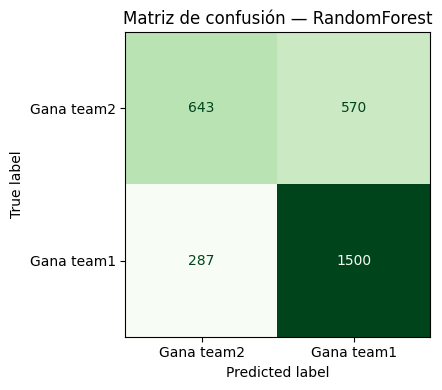

In [6]:
best = full['best_name']
entry = full['models'][best]
plot_confusion_matrix(full['y_test'], entry['y_pred'], title=f'Matriz de confusión — {best}')
plt.show()


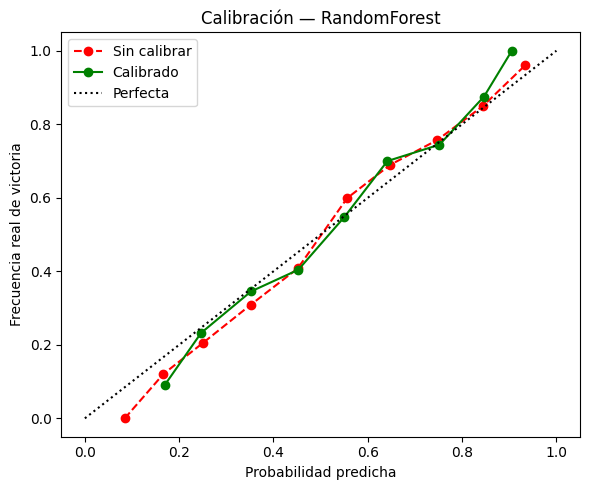

In [7]:
plot_calibration(
    full['y_test'], entry['proba_uncal'], entry['proba_cal'],
    title=f'Calibración — {best}',
)
plt.show()


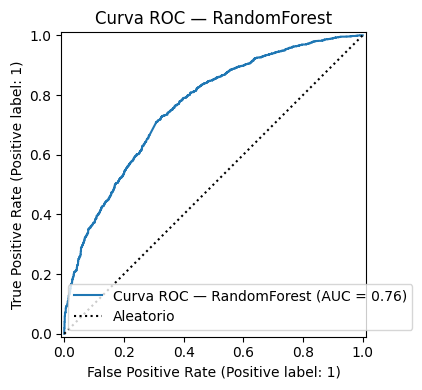

In [8]:
plot_roc(full['y_test'], entry['proba_cal'], title=f'Curva ROC — {best}')
plt.show()


## Ejemplo de predicción con odds

Tomamos un partido del set de test y lo pasamos por el mejor modelo calibrado.


In [9]:
sample = full['test'].iloc[-1]
features = {c: float(sample[c]) for c in full['feature_cols']}
pred = predict_match(
    sample['team1'], sample['team2'], features,
    model=full['best_model'], metadata=full['metadata'],
    feature_cols=full['feature_cols'],
)

print('Partido:', pred['team1'], 'vs', pred['team2'])
print('Resultado real (y):', 'team1' if sample['y'] == 1 else 'team2')
print('P(team1 gana):', round(pred['p_team1'], 4))
print('Predicción   :', pred['prediction'])
print('Odds team1   :', round(pred['odds_team1'], 2), '->', pred['tier_team1'])
print('Odds team2   :', round(pred['odds_team2'], 2), '->', pred['tier_team2'])

# Escala de tiers usada por prob_to_odds:
for p in [0.85, 0.70, 0.50, 0.35, 0.15]:
    a, b, tier = prob_to_odds(p)
    print(f'  P={p:.2f} -> odds_A={a:.2f} ({tier}) / odds_B={b:.2f}')


Partido: yoshi industries vs barbeque chicken
Resultado real (y): team2
P(team1 gana): 0.3754
Predicción   : barbeque chicken
Odds team1   : 2.66 -> Underdog
Odds team2   : 1.6 -> Favorito
  P=0.85 -> odds_A=1.18 (Favorito claro) / odds_B=6.67
  P=0.70 -> odds_A=1.43 (Favorito) / odds_B=3.33
  P=0.50 -> odds_A=2.00 (Evens/parejo) / odds_B=2.00
  P=0.35 -> odds_A=2.86 (Underdog) / odds_B=1.54
  P=0.15 -> odds_A=6.67 (Underdog claro) / odds_B=1.18
